# Which company traits help identify useful comparables?
### An exploratory X-learner analysis for stakeholder review

**Decision this informs:** which facets should we investigate before changing our comp-selection approach?

We compared facet-match signals with **human judgments of company pairs**. We investigated two representations separately: B3 text similarity and the agent’s evidence-based ratings. We did not rerun or change either matching pipeline.

**What to take away:** the B3 results suggest a shortlist of facet hypotheses to test; the agent results reveal both useful signals and substantial evidence gaps. The estimates describe this selected review cohort and do not establish causal effects or improved valuation.

The original `facet_uplift.ipynb` remains the technical/raw notebook. This presentation reads the same saved experiment.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from matplotlib.colors import ListedColormap
from IPython.display import display, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data_manifest.json").exists())
RUN = ROOT / "outputs-local/v1/facet_uplift/20261113T190330202875Z"
manifest = json.loads((RUN / "manifest.json").read_text())
features = pd.read_csv(RUN / "pair_features.csv")
summary = pd.read_csv(RUN / "facet_summary.csv")
effects = pd.read_csv(RUN / "oof_effects.csv")
folds = pd.read_csv(RUN / "fold_diagnostics.csv")
bins = pd.read_csv(RUN / "uplift_bins.csv")
primary = summary[summary.rule.eq("primary")].copy()
assert len(features) == manifest["pairs"] and features.target.nunique() == manifest["targets"]
assert not features.duplicated(["target", "comp"]).any()
assert len(summary) == 44
PRESENTATION = RUN / "presentation" / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
PRESENTATION.mkdir(parents=True, exist_ok=False)
NAMES = {"primary_services":"Services", "primary_products":"Products", "customer_segment":"Customers",
         "end_markets":"End markets", "offering_description":"Core offering", "business_model":"Business model",
         "revenue_model":"Revenue model", "value_chain_position":"Value-chain position",
         "geography_served":"Geography", "regulatory_exposure":"Regulation",
         "specialization":"Specialization", "distribution_channels":"Sales channels"}
BLUE, TEAL, ORANGE, GRAY = "#315b85", "#217f79", "#ba762c", "#a9b1bb"
plt.rcParams.update({"figure.dpi":110, "font.size":11, "axes.spines.top":False,
                     "axes.spines.right":False, "axes.titleweight":"bold"})
def save(fig, name, note):
    fig.text(.02, .012, note, fontsize=9, color="#424b55", va="bottom")
    fig.tight_layout(rect=(0,.065,1,.94))
    fig.savefig(PRESENTATION / (name + ".png"), dpi=170, bbox_inches="tight", facecolor="white")
    plt.show()
def row(source, facet, rule="primary"):
    return summary.loc[summary.source.eq(source)&summary.facet.eq(facet)&summary.rule.eq(rule)].iloc[0]
def pp(value): return f"{100*value:+.1f} pp"
def block(title, text): display(Markdown(f"**{title}**  \n{text}"))
print(f"Pinned experiment: {RUN.name}; source commit: {manifest['commit'][:8]}")
print("Figures are exported to:", PRESENTATION.relative_to(ROOT))

Pinned experiment: 20261113T190330202875Z; source commit: 44727659
Figures are exported to: outputs-local/v1/facet_uplift/20261113T190330202875Z/presentation/20261113T195347784751Z


## 1. What did we investigate?

A facet describes a company trait, such as its products, customers, or revenue model. Our question was:

> Among pairs with similar scores on their other traits, is a stronger match on this facet associated with a greater probability of receiving a human peer label?

**B3 signal:** a 50/50 blend of embedding similarity and word-overlap similarity for each facet.  
**Agent signal:** an evidence-cited rating of how closely a pair matches on each facet.

These are different measurements. Their treatments and usable pair populations differ, so a larger number in one panel does not demonstrate that one source is better.

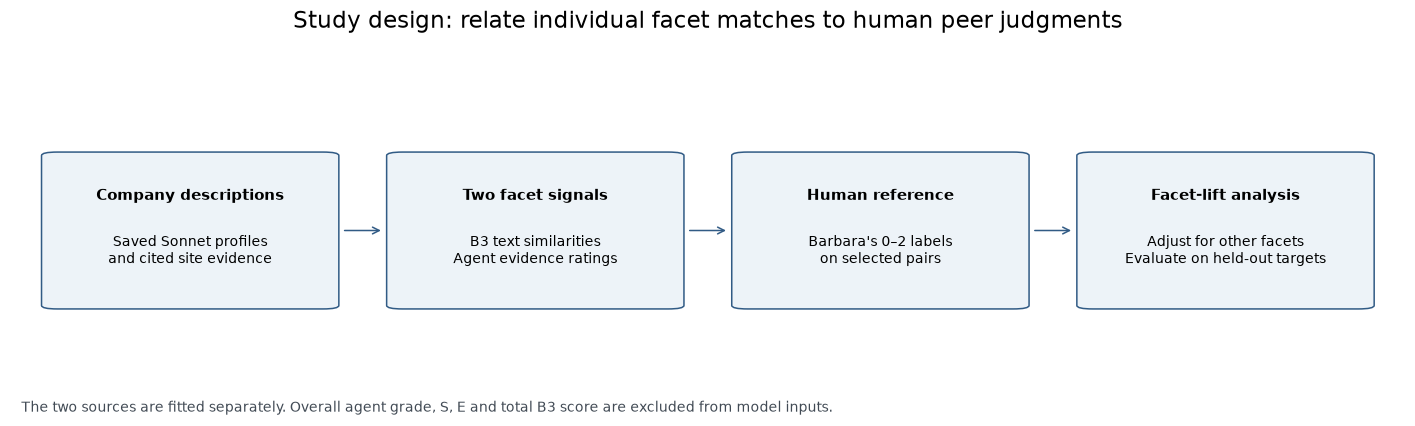

In [2]:
fig, ax = plt.subplots(figsize=(13,3.8)); ax.set(xlim=(-.025,1.025),ylim=(0,1)); ax.axis("off")
boxes=[(.01,"Company descriptions", "Saved Sonnet profiles\nand cited site evidence"),
       (.27,"Two facet signals", "B3 text similarities\nAgent evidence ratings"),
       (.53,"Human reference", "Barbara's 0–2 labels\non selected pairs"),
       (.79,"Facet-lift analysis", "Adjust for other facets\nEvaluate on held-out targets")]
for x,title,body in boxes:
    ax.add_patch(FancyBboxPatch((x,.24),.20,.52,boxstyle="round,pad=.012",facecolor="#edf3f8",edgecolor=BLUE))
    ax.text(x+.10,.62,title,ha="center",va="center",weight="bold",fontsize=10)
    ax.text(x+.10,.43,body,ha="center",va="center",fontsize=9)
for a,b in zip(boxes[:-1],boxes[1:]):
    ax.annotate("",xy=(b[0]-.014,.5),xytext=(a[0]+.214,.5),arrowprops={"arrowstyle":"->","color":BLUE})
fig.suptitle("Study design: relate individual facet matches to human peer judgments",fontsize=15)
save(fig,"01_approach","The two sources are fitted separately. Overall agent grade, S, E and total B3 score are excluded from model inputs.")

## 2. What evidence do we have?

The reference is a single reviewer’s assessment of a selected candidate list. This is a development study; some of these labels already informed earlier pipeline choices. It is not a new independent benchmark.

We define an **acceptable peer** as either direct (grade 2) or adjacent (grade 1). The experiment does not separately establish which facets distinguish direct from adjacent peers.

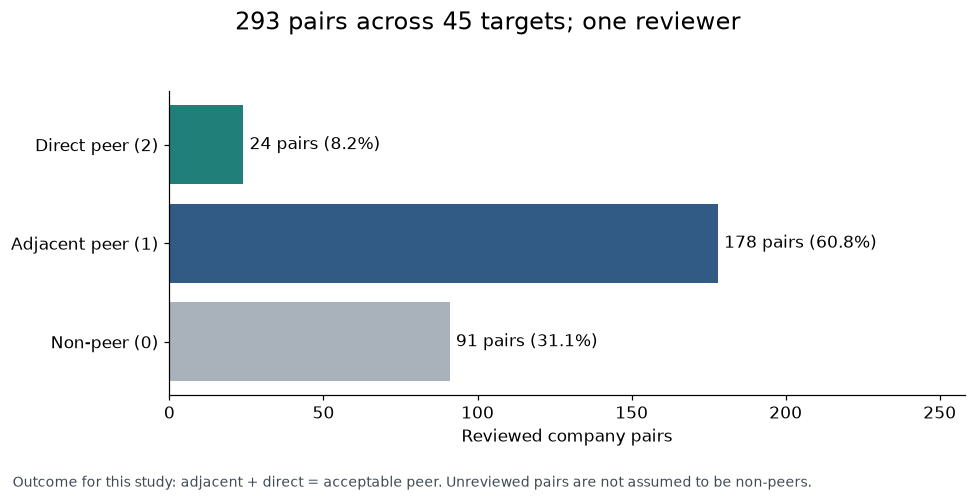

**Reading the cohort**  
202 of 293 pairs (68.9%) are acceptable peers. Only 24 are direct peers; conclusions apply to the combined peer outcome.

In [3]:
counts=features.score_barbara.value_counts().reindex([0,1,2],fill_value=0)
fig,ax=plt.subplots(figsize=(9,4.5))
bars=ax.barh(["Non-peer (0)","Adjacent peer (1)","Direct peer (2)"],counts,color=[GRAY,BLUE,TEAL])
for bar,n in zip(bars,counts): ax.text(n+2,bar.get_y()+bar.get_height()/2,f"{n} pairs ({n/len(features):.1%})",va="center")
ax.set(xlim=(0,max(counts)*1.45),xlabel="Reviewed company pairs")
fig.suptitle(f"{len(features)} pairs across {features.target.nunique()} targets; one reviewer",fontsize=16)
save(fig,"02_review_cohort","Outcome for this study: adjacent + direct = acceptable peer. Unreviewed pairs are not assumed to be non-peers.")
block("Reading the cohort",f"{int(counts[1]+counts[2])} of {len(features)} pairs ({(counts[1]+counts[2])/len(features):.1%}) are acceptable peers. Only {int(counts[2])} are direct peers; conclusions apply to the combined peer outcome.")

## 3. How did we learn and evaluate facet lift?

For each facet, the X-learner compares stronger and weaker matches while using the other facet scores as context:

1. Learn peer probabilities for strong-match and weak-match training pairs.
2. Estimate each training pair’s missing alternative outcome.
3. Learn patterns in those estimated differences and apply them to held-out targets.

We rotate through five groups of targets. A company’s target pairs stay together, so its own labels cannot enter training when it is held out. Three additional groups inside training generate the estimated differences. Comp companies can still appear across target groups.

Held-out labels can assess **peer-probability predictions**. They cannot reveal the true effect of changing a facet match for the same pair.

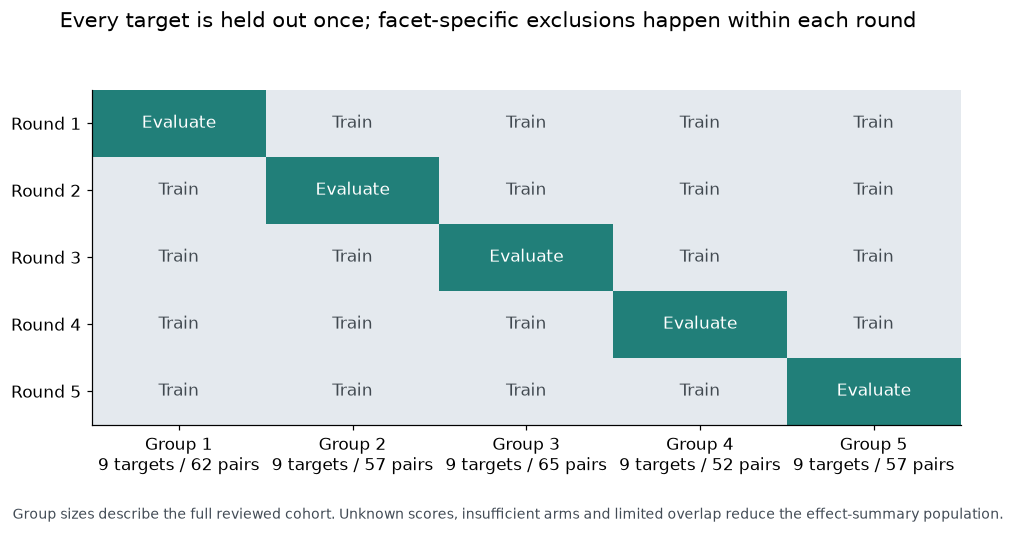

In [4]:
import sys
sys.path.insert(0,str(ROOT / "v1/scripts"))
from facet_uplift import group_splits
splits=list(group_splits(features.target.to_numpy()))
fig,ax=plt.subplots(figsize=(9,4.8))
ax.imshow(np.eye(5),cmap=ListedColormap(["#e4e9ee",TEAL]),vmin=0,vmax=1,aspect="auto")
for i,(train,test) in enumerate(splits):
    for j in range(5):
        ax.text(j,i,"Evaluate" if i==j else "Train",ha="center",va="center",color="white" if i==j else "#414950")
ax.set_xticks(range(5),[f"Group {i+1}\n{features.iloc[te].target.nunique()} targets / {len(te)} pairs" for i,(_,te) in enumerate(splits)])
ax.set_yticks(range(5),[f"Round {i+1}" for i in range(5)])
fig.suptitle("Every target is held out once; facet-specific exclusions happen within each round",fontsize=14)
save(fig,"03_target_validation","Group sizes describe the full reviewed cohort. Unknown scores, insufficient arms and limited overlap reduce the effect-summary population.")

## 4. Which facets show positive adjusted lift?

The dot is estimated average lift in the probability of an acceptable human rating, expressed in **percentage points**. For example, a hypothetical change from 50% to 70% would be +20 percentage points; that is an illustration, not an observed before/after change for any pair.

Each target receives equal weight in the summary after filtering to cases with adequate estimated strong/weak-match overlap. Gray facets lack an estimate; orange estimates use incomplete evaluation rounds.

The ranges below bootstrap targets while **holding fitted predictions fixed**. They omit refitting, threshold, reviewer and candidate-selection uncertainty. They are not full causal confidence intervals or corrected tests of significance.

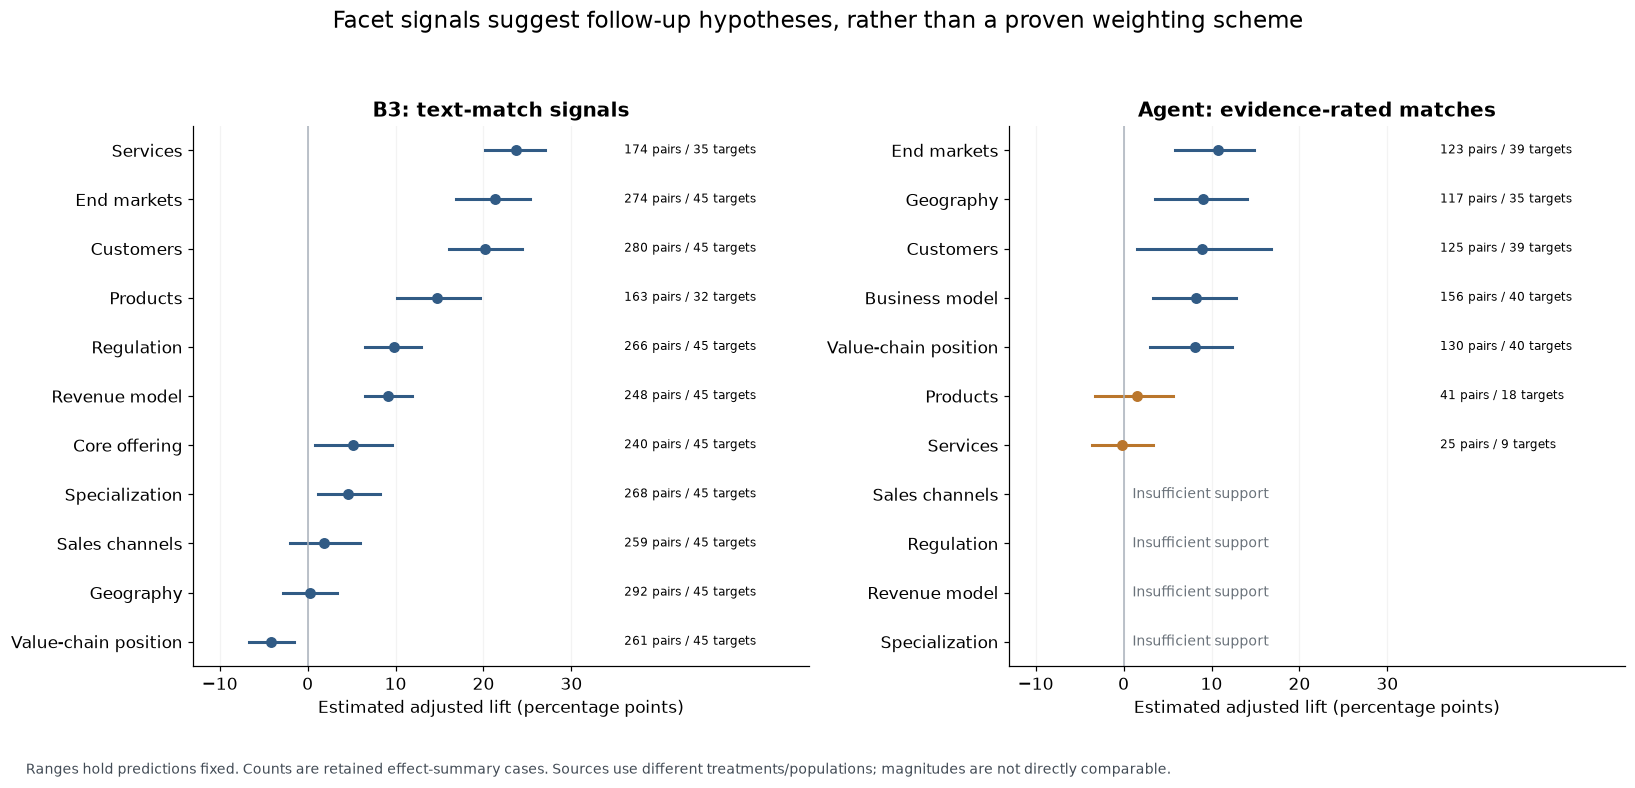

**Largest complete primary estimates within B3**  
Services +23.7 pp; End markets +21.3 pp; Customers +20.2 pp; Products +14.7 pp. This ordering is descriptive, not a statistically established ranking of facets.

**Largest complete primary estimates within AGENT**  
End markets +10.7 pp; Geography +9.0 pp; Customers +8.9 pp; Business model +8.3 pp. This ordering is descriptive, not a statistically established ranking of facets.

In [5]:
fig,axes=plt.subplots(1,2,figsize=(15,7.2),sharex=True)
for ax,source,title in zip(axes,["b3","agent"],["B3: text-match signals","Agent: evidence-rated matches"]):
    part=primary[primary.source.eq(source)].sort_values("mean_uplift",ascending=False,na_position="last").reset_index(drop=True)
    labels=[]
    for i,r in part.iterrows():
        labels.append(NAMES[r.facet])
        if pd.notna(r.mean_uplift):
            color=BLUE if r.status=="complete" else ORANGE
            ax.plot([100*r.uplift_ci_low,100*r.uplift_ci_high],[i,i],color=color,lw=2)
            ax.scatter(100*r.mean_uplift,i,color=color,s=38,zorder=3)
            ax.text(36,i,f"{int(r.overlap_pairs)} pairs / {int(r.overlap_targets)} targets",va="center",fontsize=8)
        else: ax.text(1,i,"Insufficient support",va="center",color="#6a727a",fontsize=9)
    ax.set_yticks(range(len(part)),labels);ax.set_ylim(len(part)-.5,-.5);ax.axvline(0,color=GRAY,lw=1)
    ax.set(title=title,xlabel="Estimated adjusted lift (percentage points)",xlim=(-13,57))
    ax.set_xticks([-10,0,10,20,30]);ax.grid(axis="x",alpha=.15)
fig.suptitle("Facet signals suggest follow-up hypotheses, rather than a proven weighting scheme",fontsize=15)
save(fig,"04_facet_lift","Ranges hold predictions fixed. Counts are retained effect-summary cases. Sources use different treatments/populations; magnitudes are not directly comparable.")
for source in ["b3","agent"]:
    p=primary[(primary.source==source)&primary.status.eq("complete")].sort_values("mean_uplift",ascending=False)
    text="; ".join(f"{NAMES[r.facet]} {pp(r.mean_uplift)}" for _,r in p.head(4).iterrows())
    block(f"Largest complete primary estimates within {source.upper()}",text+". This ordering is descriptive, not a statistically established ranking of facets.")

## 5. Do the conclusions change with a stricter match definition?

**B3:** primary compares above vs at/below the training median; the stricter version compares the upper and lower thirds.  
**Agent:** primary compares 75/100 vs 0/25/50; the stricter version removes adjacent matches rated 50.

The comparison changes both the contrast and the included pairs. A larger strict estimate may reflect more distinct groups, a different sample, or estimation sensitivity. It does not automatically establish a stronger or more reliable effect.

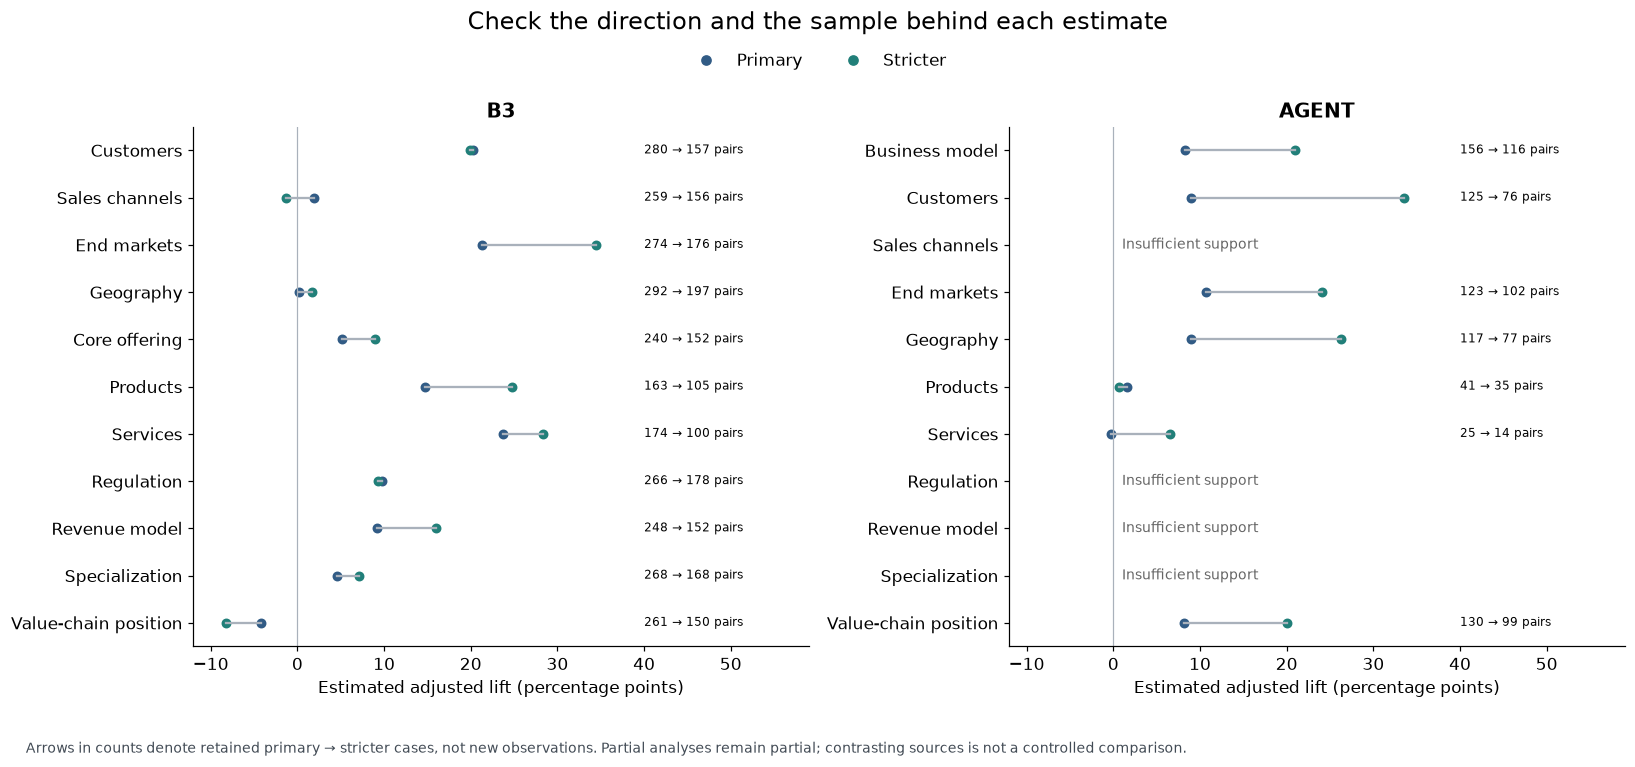

**Priority B3 hypotheses stay positive under both comparisons**  
Services: +23.7 pp → +28.3 pp (174 → 100 retained pairs); End markets: +21.3 pp → +34.5 pp (274 → 176 retained pairs); Customers: +20.2 pp → +19.9 pp (280 → 157 retained pairs); Products: +14.7 pp → +24.7 pp (163 → 105 retained pairs). This is sensitivity to one alternative threshold definition, not broad robustness validation.

In [6]:
fig,axes=plt.subplots(1,2,figsize=(15,7),sharex=True)
for ax,source in zip(axes,["b3","agent"]):
    names=primary.loc[primary.source.eq(source)].sort_values("facet").facet.tolist()
    for i,f in enumerate(names):
        a,b=row(source,f),row(source,f,"extreme")
        if pd.isna(a.mean_uplift) or pd.isna(b.mean_uplift):
            ax.text(1,i,"Insufficient support",va="center",fontsize=9,color="#666666"); continue
        ax.plot([100*a.mean_uplift,100*b.mean_uplift],[i,i],color=GRAY)
        ax.scatter(100*a.mean_uplift,i,color=BLUE,s=30,label="Primary" if i==0 else None)
        ax.scatter(100*b.mean_uplift,i,color=TEAL,s=30,label="Stricter" if i==0 else None)
        ax.text(40,i,f"{int(a.overlap_pairs)} → {int(b.overlap_pairs)} pairs",fontsize=8,va="center")
    ax.set_yticks(range(len(names)),[NAMES[f] for f in names]);ax.set_ylim(len(names)-.5,-.5)
    ax.set(title=source.upper(),xlabel="Estimated adjusted lift (percentage points)",xlim=(-12,59))
    ax.axvline(0,color=GRAY,lw=.8)
# Use explicit handles so missing first facets do not suppress the legend.
from matplotlib.lines import Line2D
fig.legend(handles=[Line2D([],[],marker="o",linestyle="",color=BLUE,label="Primary"),Line2D([],[],marker="o",linestyle="",color=TEAL,label="Stricter")],loc="upper center",bbox_to_anchor=(.5,.945),ncol=2,frameon=False)
fig.suptitle("Check the direction and the sample behind each estimate",fontsize=16)
save(fig,"05_threshold_sensitivity","Arrows in counts denote retained primary → stricter cases, not new observations. Partial analyses remain partial; contrasting sources is not a controlled comparison.")
shortlist=["primary_services","end_markets","customer_segment","primary_products"]
items=[]
for f in shortlist:
 a,b=row("b3",f),row("b3",f,"extreme")
 assert a.mean_uplift>0 and b.mean_uplift>0
 items.append(f"{NAMES[f]}: {pp(a.mean_uplift)} → {pp(b.mean_uplift)} ({int(a.overlap_pairs)} → {int(b.overlap_pairs)} retained pairs)")
block("Priority B3 hypotheses stay positive under both comparisons","; ".join(items)+". This is sensitivity to one alternative threshold definition, not broad robustness validation.")

## 6. Where is more evidence needed?

An estimate needs enough pairs on **both** sides of a match comparison across enough targets. A facet can fail because evidence is missing, strong matches are rare, or a training fold lacks enough examples. Missing estimates cannot be interpreted as zero usefulness.

For the agent, unknown means the evidence was insufficient. It is never converted to an evidenced mismatch.

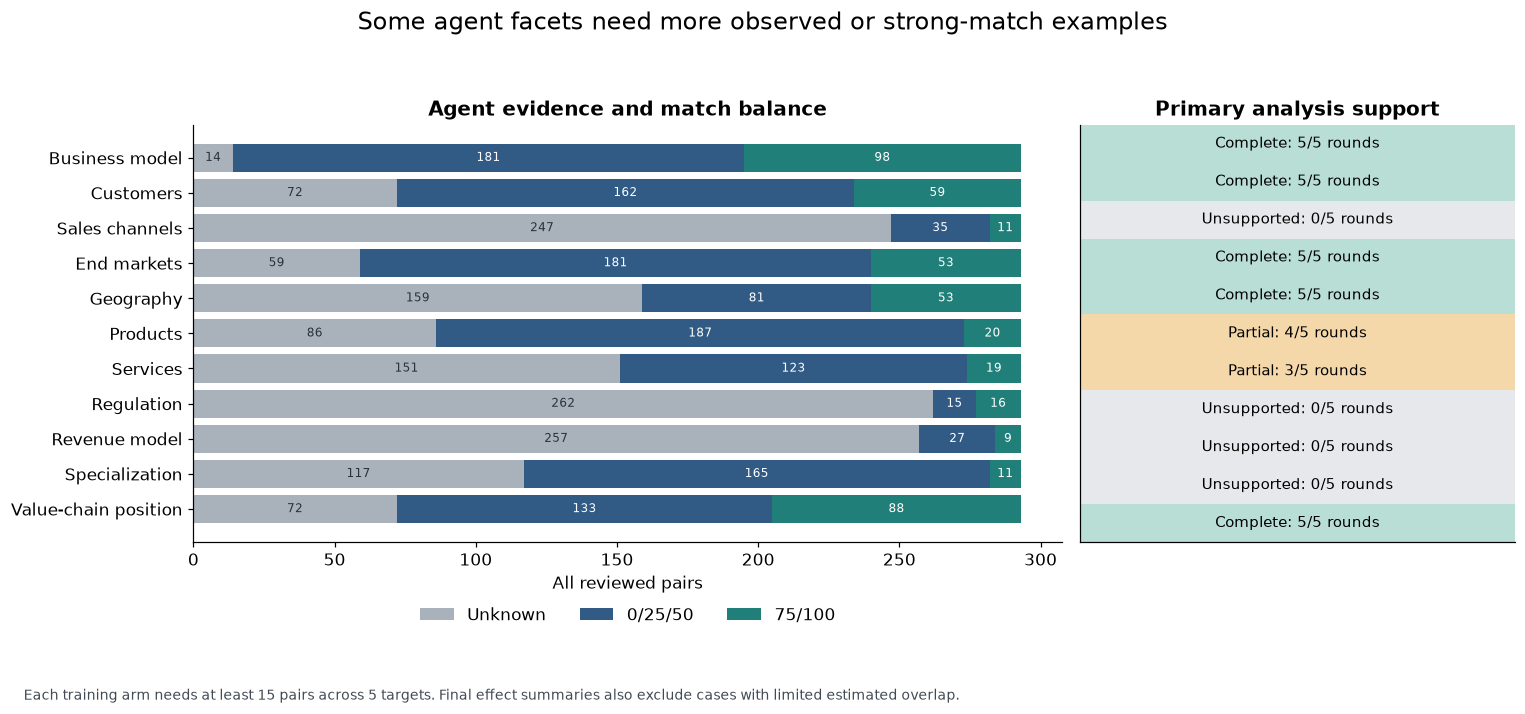

**Coverage finding**  
B3: 11 complete primary analyses. Agent: 5 complete, 2 partial, 4 unsupported. Products have only 20 strong-match pairs; services have 19. Revenue-model evidence is missing for 257 of 293 pairs.

In [7]:
part=primary[primary.source.eq("agent")].sort_values("facet").reset_index(drop=True)
fig,(ax1,ax2)=plt.subplots(1,2,figsize=(14,6.5),gridspec_kw={"width_ratios":[2,1]})
y=np.arange(len(part));left=np.zeros(len(part))
for category,color,selector in [("Unknown",GRAY,lambda v:v.isna()),("0/25/50",BLUE,lambda v:v.le(50)),("75/100",TEAL,lambda v:v.ge(75))]:
    vals=np.array([int(selector(features['agent__'+f]).sum()) for f in part.facet])
    ax1.barh(y,vals,left=left,color=color,label=category)
    for i,(n,l) in enumerate(zip(vals,left)):
        if n>=9:ax1.text(l+n/2,i,str(n),ha="center",va="center",fontsize=8,color="white" if category!="Unknown" else "#26323d")
    left+=vals
ax1.set_yticks(y,[NAMES[f] for f in part.facet]);ax1.invert_yaxis();ax1.set(xlabel="All reviewed pairs",title="Agent evidence and match balance")
ax1.legend(loc="upper center",bbox_to_anchor=(.5,-.12),ncol=3,frameon=False)
status=np.array([[0 if r.folds_ok==0 else 1 if r.folds_ok<5 else 2] for _,r in part.iterrows()])
ax2.imshow(status,cmap=ListedColormap(["#e6e8eb","#f4d8aa","#b9ded5"]),vmin=0,vmax=2,aspect="auto")
for i,r in part.iterrows():
    label="Unsupported" if r.folds_ok==0 else "Partial" if r.folds_ok<5 else "Complete"
    ax2.text(0,i,f"{label}: {int(r.folds_ok)}/5 rounds",ha="center",va="center",fontsize=10)
ax2.set_yticks([]);ax2.set_xticks([]);ax2.set_title("Primary analysis support")
fig.suptitle("Some agent facets need more observed or strong-match examples",fontsize=16)
save(fig,"06_agent_support","Each training arm needs at least 15 pairs across 5 targets. Final effect summaries also exclude cases with limited estimated overlap.")
complete=int(part.status.eq("complete").sum()); partial=int(part.folds_ok.between(1,4).sum());unsupported=int(part.folds_ok.eq(0).sum())
block("Coverage finding",f"B3: 11 complete primary analyses. Agent: {complete} complete, {partial} partial, {unsupported} unsupported. Products have only {int(features.agent__primary_products.ge(75).sum())} strong-match pairs; services have {int(features.agent__primary_services.ge(75).sum())}. Revenue-model evidence is missing for {int(features.agent__revenue_model.isna().sum())} of {len(features)} pairs.")

## 7. Recommended investigations

These are next experiments to prioritize, not changes to matching weights:

1. **Test the core business-match hypotheses.** Prioritize services, end markets, customers and products in B3. They show positive estimates under both contrasts. Obtain new reviewer labels, then compare frozen matching runs with and without each facet.
2. **Improve agent evidence before judging unsupported facets.** Target revenue model, regulation and sales channels for better source coverage; obtain more strong-match products/services examples. Evidence collection alone will not solve every imbalance.
3. **Inspect disagreements between measurements and diagnostics.** Value-chain position is negative in the B3 analysis but positive in the agent analysis; the measurements, contrasts and retained groups differ. Review concrete cases before removing or reweighting the facet. Customer ratings also show disagreement between the X-learner estimate and a second adjusted diagnostic.
4. **Use weaker signals as lower-priority hypotheses.** B3 geography is near zero; sales-channel estimates are small and change sign under the stricter contrast. This is insufficient evidence to conclude these facets are universally irrelevant.
5. **Validate beyond the current reviewer and candidate list.** Add an independent reviewer and additional targets. Test direct peers separately once enough direct labels exist. Any subsequent changes to B3 or B3 + agent review require their own evaluation.

**No new facet weighting is recommended from this experiment alone.**

## Technical appendix: interpret the estimates carefully

The outcome is a reviewer label, not revenue or valuation. The match groups were not randomized. Company traits and candidate selection may confound the results. Consequently, the estimated lift is an adjusted association within this selected cohort.

The model uses regularized logistic response/propensity models and ridge effect models, with target-weighted training. The estimator may produce individual differences outside the valid probability-difference range; those are instability flags, not literal probabilities.

A second adjusted calculation (DR pseudo-effects) can disagree with the X-learner and is not ground truth. Held-out response AUC/Brier metrics do not validate treatment-effect accuracy. The tables below retain those diagnostics for review rather than treating every positive estimate as an established finding.

In [8]:
a=row("agent","customer_segment")
block("Customer-rating diagnostic disagreement",f"Primary agent estimate: {pp(a.mean_uplift)}; DR adjusted diagnostic: {pp(a.dr_adjusted_difference)}. These methods do not agree on the sign, so the positive estimate needs scrutiny.")
violations=effects.assign(out_of_bounds=effects.uplift.abs()>1).groupby(["source","rule"]).agg(predictions=("uplift","size"),out_of_bounds=("out_of_bounds","sum"))
display(violations)
t=summary.copy(); t['Facet']=t.facet.map(NAMES)
cols=['source','Facet','rule','status','predicted_pairs','overlap_pairs','overlap_targets','mean_uplift','uplift_ci_low','uplift_ci_high','dr_adjusted_difference','brier','baseline_brier','response_auc']
display(t[cols].round(4))
display(folds[~folds.status.eq('ok')][['source','facet','rule','fold','controls','treated','targets_arm_0','targets_arm_1','unknown_test','middle_test','status']])

**Customer-rating diagnostic disagreement**  
Primary agent estimate: +8.9 pp; DR adjusted diagnostic: -3.1 pp. These methods do not agree on the sign, so the positive estimate needs scrutiny.

predictions  out_of_bounds
source rule                               
agent  extreme          864              6
       primary         1345             11
b3     extreme         2042              6
       primary         3030              0

,source,Facet,rule,status,predicted_pairs,overlap_pairs,overlap_targets,mean_uplift,uplift_ci_low,uplift_ci_high,dr_adjusted_difference,brier,baseline_brier,response_auc
0,agent,Business model,extreme,complete,186,116.0,38.0,0.2092,0.1427,0.2786,0.0645,0.1582,0.1895,0.7289
1,agent,Business model,primary,complete,279,156.0,40.0,0.0828,0.0332,0.1278,0.0302,0.1533,0.2133,0.8030
2,agent,Customers,extreme,complete,128,76.0,38.0,0.3358,0.2479,0.4217,0.2605,0.1357,0.2386,0.8690
3,agent,Customers,primary,complete,221,125.0,39.0,0.0893,0.0157,0.1681,-0.0309,0.1358,0.2197,0.8647
4,agent,Sales channels,extreme,partial_or_unsupported,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,agent,Sales channels,primary,partial_or_unsupported,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,agent,End markets,extreme,complete,135,102.0,39.0,0.2407,0.1466,0.3331,0.3356,0.1317,0.2420,0.8832
7,agent,End markets,primary,complete,234,123.0,39.0,0.1072,0.0588,0.1488,0.1073,0.1429,0.2138,0.8531
8,agent,Geography,extreme,complete,86,77.0,27.0,0.2627,0.1933,0.3361,0.2209,0.1380,0.2049,0.8414
9,agent,Geography,primary,complete,134,117.0,35.0,0.0898,0.0359,0.1404,0.0668,0.1563,0.2103,0.8270


,source,facet,rule,fold,controls,treated,targets_arm_0,targets_arm_1,unknown_test,middle_test,status
111,agent,primary_products,primary,1,165,14,32,8,29,0,insufficient_support
116,agent,primary_products,extreme,1,122,14,32,8,29,9,insufficient_support
121,agent,primary_services,primary,1,86,14,23,8,15,0,insufficient_support
123,agent,primary_services,primary,3,105,14,24,6,29,0,insufficient_support
126,agent,primary_services,extreme,1,40,14,20,8,15,10,insufficient_support
128,agent,primary_services,extreme,3,58,14,21,6,29,9,insufficient_support
160,agent,revenue_model,primary,0,23,5,12,4,54,0,insufficient_support
161,agent,revenue_model,primary,1,24,7,14,5,52,0,insufficient_support
162,agent,revenue_model,primary,2,22,9,12,7,60,0,insufficient_support
163,agent,revenue_model,primary,3,22,7,13,6,45,0,insufficient_support


## Reproducibility and further reading

The presentation reads the pinned experiment CSVs; Run All does not refit the X-learner or call an LLM. Each execution exports six figures to a new timestamped presentation folder. Existing raw results and the technical notebook are preserved.

- Technical notebook: `facet_uplift.ipynb`.
- Full methodology and fixed settings: `../FACET_UPLIFT.md`.
- Experiment runner: `../scripts/facet_uplift.py`.
- Saved run: `outputs-local/v1/facet_uplift/20261113T190330202875Z/`.

The next deliverable should be evidence from new labels and controlled pipeline experiments, rather than an automatic weight update based on this notebook.

In [9]:
presentation_manifest={"source_run":RUN.name,"source_commit":manifest['commit'],"notebook":"facet_uplift_stakeholder.ipynb",
    "input_sha256":{p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in [RUN/'manifest.json',RUN/'pair_features.csv',RUN/'facet_summary.csv',RUN/'oof_effects.csv',RUN/'fold_diagnostics.csv']},
    "figures":sorted(p.name for p in PRESENTATION.glob('*.png')),
    "interpretation":"Exploratory adjusted associations; fixed-prediction bootstrap intervals; different source contrasts and populations."}
assert len(presentation_manifest['figures'])==6
(PRESENTATION/'manifest.json').write_text(json.dumps(presentation_manifest,indent=2)+'\n')
print('Exported six stakeholder figures. Original experiment files were read only.')

Exported six stakeholder figures. Original experiment files were read only.
